# Sprint 4 - Modelagem Linear para Aprendizado de Máquina

## Integrantes

Augusto de Souza Avila | RM: 570839  
Davi Simoncelo | RM: 571738  
João Pedro Sousa | RM: 573962  
Matheus Evangelista | RM: 568593  
Murilo Lima de Carvalho | RM: 570156

## Dataset - Renewable Energy Production Dataset (2010-2020)

Este dataset oferece uma visão detalhada da produção de energia renovável (solar, eólica e hidrelétrica), classificada em categorias distintas com base nos níveis de produção. Os dados são complementados por parâmetros ambientais, como temperatura, velocidade do vento, radiação solar e precipitação, tornando-os ideais para modelos de aprendizado de máquina baseados em classificação.

Fonte: https://www.kaggle.com/datasets/itsrohithere/renewable-energy-production-dataset-2010-2020/data

Target = Energy_Class

# 1. Análise do Dataset

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/JP-Sousa/Sprint-4-MLAM/refs/heads/main/Renewable_Energy_Data.csv')

NOMES_CLASSES = ["Low", "Medium", "High"]

In [3]:
df.head()

,Region,Energy_Source,Temperature_C,Wind_Speed_m_s,Solar_Radiation_kWh_m2,Rainfall_mm,Season,Efficiency_Ratio,Lagged_Production_MWh,Combined_Weather_Index,Energy_Class
0,North,Hydro,13.820937,14.362462,8.834648,3.350827,Winter,125.449109,1419.514155,1.565158,Medium
1,North,Solar,36.972782,19.110474,4.483191,48.767157,Winter,16.325089,4769.329958,0.621331,Low
2,East,Hydro,33.972875,0.364652,5.104325,40.848695,Winter,155.637061,1005.077719,0.156378,High
3,South,Solar,-2.965160,3.915560,6.265925,42.627371,Spring,675.516566,6294.250931,-5.180996,High
4,North,Wind,-3.813486,0.151257,9.263826,46.898262,Spring,626.048277,5550.263638,-3.346412,Medium


In [4]:
print("\nValores ausentes por coluna:")
display(df.isna().sum().rename("valores ausentes").to_frame())

print("\nDistribuição da variável-alvo:")
display(df['Energy_Class'].value_counts())



Valores ausentes por coluna:


,valores ausentes
Region,0
Energy_Source,0
Temperature_C,0
Wind_Speed_m_s,0
Solar_Radiation_kWh_m2,0
Rainfall_mm,0
Season,0
Efficiency_Ratio,0
Lagged_Production_MWh,0
Combined_Weather_Index,0



Distribuição da variável-alvo:


,count
Energy_Class,
High,486
Medium,336
Low,178


In [5]:
# Encoding da variável-alvo (Energy_Class)

df['Energy_Class'] = df['Energy_Class'].map({'Low': 0, 'Medium': 1, 'High': 2})

In [6]:
df.head()

,Region,Energy_Source,Temperature_C,Wind_Speed_m_s,Solar_Radiation_kWh_m2,Rainfall_mm,Season,Efficiency_Ratio,Lagged_Production_MWh,Combined_Weather_Index,Energy_Class
0,North,Hydro,13.820937,14.362462,8.834648,3.350827,Winter,125.449109,1419.514155,1.565158,1
1,North,Solar,36.972782,19.110474,4.483191,48.767157,Winter,16.325089,4769.329958,0.621331,0
2,East,Hydro,33.972875,0.364652,5.104325,40.848695,Winter,155.637061,1005.077719,0.156378,2
3,South,Solar,-2.965160,3.915560,6.265925,42.627371,Spring,675.516566,6294.250931,-5.180996,2
4,North,Wind,-3.813486,0.151257,9.263826,46.898262,Spring,626.048277,5550.263638,-3.346412,1


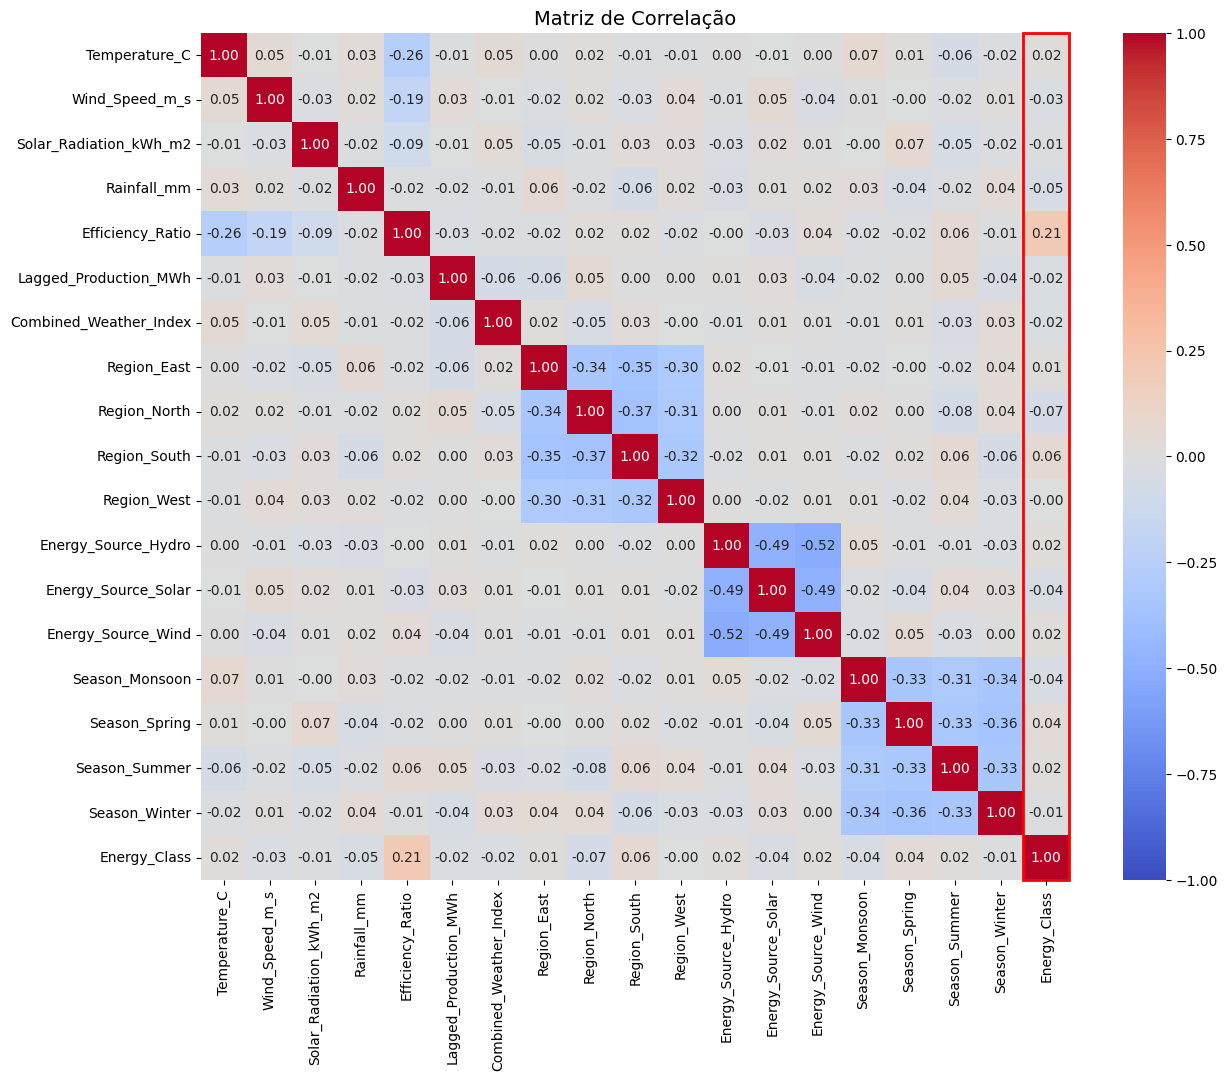

,correlação com Energy_Class
Efficiency_Ratio,0.211202
Region_North,-0.065402
Region_South,0.056317
Rainfall_mm,-0.045958
Season_Monsoon,-0.044988
Season_Spring,0.039044
Energy_Source_Solar,-0.035149
Wind_Speed_m_s,-0.027079
Combined_Weather_Index,-0.024515
Lagged_Production_MWh,-0.023716


In [7]:
# Convertendo todas as variáveis categóricas de texto em numéricas (One-Hot Encoding)
df_encoded = pd.get_dummies(df, columns=['Region', 'Energy_Source', 'Season'], drop_first=False)

coluna_alvo = df_encoded.pop('Energy_Class')
df_encoded.insert(len(df_encoded.columns), 'Energy_Class', coluna_alvo)

# Matriz de correlação
correlacao = df_encoded.corr()

# Heatmap
fig, ax = plt.subplots(figsize=(14, 11))

sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)

n_colunas = correlacao.shape[1]
rect = plt.Rectangle((n_colunas - 1, 0), 1, n_colunas, fill=False, edgecolor='red', lw=2, clip_on=False)
ax.add_patch(rect)

plt.title("Matriz de Correlação", fontsize=14)
plt.show()

# Associações com o alvo, ordenadas pela magnitude absoluta.
correlacoes_com_alvo = (
    correlacao['Energy_Class']
    .drop('Energy_Class')
    .sort_values(key=lambda serie: serie.abs(), ascending=False)
    .rename("correlação com Energy_Class")
    .to_frame()
)
display(correlacoes_com_alvo)

# 2. Análise da Matriz de Correlação e Seleção dos Atributos


Com base na matriz de correlação gerada e na ordenação das correlações absolutas com a variável-alvo `Energy_Class`, podemos realizar as seguintes observações:

1. **Baixa Correlação Linear Geral:**
   * A variável `Efficiency_Ratio` apresenta a maior correlação linear com o alvo, porém ainda é considerada uma correlação fraca a moderada (~0.21).
   * Todas as outras variáveis numéricas e dummy/one-hot (como as regiões, fontes de energia e estações do ano) apresentam correlações extremamente baixas com o alvo (abaixo de 0.07 em módulo).

2. **Ausência de Multicolinearidade Forte:**
   * Entre as variáveis preditoras numéricas (`Temperature_C`, `Wind_Speed_m_s`, `Solar_Radiation_kWh_m2`, `Rainfall_mm`, `Efficiency_Ratio`, `Lagged_Production_MWh`), as correlações são próximas de zero, exceto por uma correlação fraca e negativa entre `Temperature_C` e `Efficiency_Ratio` (~ -0.26).
   * Isso indica que não há redundância de informação (multicolinearidade) óbvia que nos force a remover variáveis numéricas para evitar instabilidade em modelos lineares.

Portanto **É mais apropriado utilizar todas as features disponíveis**. Pois:

* Como as correlações lineares individuais de quase todas as variáveis com o alvo são muito baixas, se descartássemos features puramente por possuírem baixa correlação linear individual, acabaríamos excluindo quase todo o dataset (restando apenas `Efficiency_Ratio`).
* Relações complexas ou não-lineares, além de interações combinadas entre múltiplos atributos (ex: vento + velocidade do vento para geração eólica), podem ser cruciais para que o modelo de classificação estabeleça sua fronteira de decisão. Modelos lineares com regularização (como a Regressão Logística com penalidade L1 ou L2) conseguem lidar com features de menor importância de forma automática, aplicando coeficientes próximos a zero sem perda de performance.
* Por isso, manter todas as variáveis nos dá uma maior garantia de que não estamos jogando fora informações potencialmente úteis quando combinadas.

In [8]:
# Definindo as features (X) e a variável-alvo (y)
y = df['Energy_Class']
X = df.drop(columns=['Energy_Class'])

print("Dimensões de X:", X.shape)
print("Dimensões de y:", y.shape)

Dimensões de X: (1000, 10)
Dimensões de y: (1000,)


In [9]:
# Define tipos de colunas depois da seleção.
X_modelo = X.copy()
colunas_numericas_modelo = X_modelo.select_dtypes(include=np.number).columns.tolist()
colunas_categoricas_modelo = X_modelo.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# 3. Definição e Aplicação do Modelo

## Modelo escolhido: Regressão Logística

Para este problema de classificação multiclasse (classes `Low` [0], `Medium` [1] e `High` [2]), o modelo linear selecionado do `scikit-learn` é a **Regressão Logística (Logistic Regression)** via classe `sklearn.linear_model.LogisticRegression`.

Apesar do nome, ela é um modelo linear de classificação: para cada classe, combina as features em um escore linear, do tipo

$$
s_k(x) = w_k^T x + b_k
$$

Na classificação multiclasse, o modelo estima escores/probabilidades por classe e escolhe a classe mais provável. A fronteira entre duas classes aparece onde seus escores se igualam:

$$
(w_i - w_j)^T x + (b_i - b_j) = 0
$$

que é uma fronteira linear (um hiperplano) no espaço de features após o pré-processamento. O encoding one-hot transforma as categorias em colunas numéricas e a padronização coloca as features numéricas em escalas comparáveis.

In [10]:
# Cria um pipeline novo para cada cenário, incluindo um pré-processador independente.
def criar_modelo():
    transformadores = []

    if colunas_numericas_modelo:
        transformacao_numerica = Pipeline(steps=[
            ("imputacao", SimpleImputer(strategy="median")),
            ("padronizacao", StandardScaler()),
        ])
        transformadores.append(("numericas", transformacao_numerica, colunas_numericas_modelo))

    if colunas_categoricas_modelo:
        transformacao_categorica = Pipeline(steps=[
            ("imputacao", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
        ])
        transformadores.append(("categoricas", transformacao_categorica, colunas_categoricas_modelo))

    preprocessador = ColumnTransformer(transformers=transformadores, remainder="drop")
    return Pipeline(steps=[
        ("preprocessamento", preprocessador),
        ("classificador", LogisticRegression(solver="lbfgs", max_iter=2000, C=1.0)),
    ])

print("Colunas numéricas usadas no modelo:", colunas_numericas_modelo)
print("Colunas categóricas usadas no modelo:", colunas_categoricas_modelo)

Colunas numéricas usadas no modelo: ['Temperature_C', 'Wind_Speed_m_s', 'Solar_Radiation_kWh_m2', 'Rainfall_mm', 'Efficiency_Ratio', 'Lagged_Production_MWh', 'Combined_Weather_Index']
Colunas categóricas usadas no modelo: ['Region', 'Energy_Source', 'Season']


# 4. Treino e Teste nos dois cenários

In [11]:
def avaliar_cenario(nome_cenario, proporcao_teste):
    # Divide os dados em treino e teste, mantendo a proporção das classes.
    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X_modelo,
        y,
        test_size=proporcao_teste,
        random_state=1,
        stratify=y,
    )

    # Treina o modelo e gera previsões para o conjunto de teste.
    modelo = criar_modelo()
    modelo.fit(X_treino, y_treino)
    previsoes = modelo.predict(X_teste)

    # Calcula as métricas gerais do cenário.
    metricas = {
        "Cenário": nome_cenario,
        "Treino (%)": round((1 - proporcao_teste) * 100),
        "Teste (%)": round(proporcao_teste * 100),
        "N treino": len(y_treino),
        "N teste": len(y_teste),
        "Acurácia": accuracy_score(y_teste, previsoes),
        "Precisão macro": precision_score(
            y_teste,
            previsoes,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
        "Recall macro": recall_score(
            y_teste,
            previsoes,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
        # Baseline: proporção de exemplos da classe mais frequente no treino.
        "Acurácia baseline": (y_teste == y_treino.mode().iloc[0]).mean(),
    }

    # Calcula a matriz de confusão.
    matriz = confusion_matrix(
        y_teste,
        previsoes,
        labels=[0, 1, 2],
    )

    # Gera o relatório de classificação.
    relatorio = classification_report(
        y_teste,
        previsoes,
        labels=[0, 1, 2],
        target_names=NOMES_CLASSES,
        output_dict=True,
        zero_division=0,
    )

    # Guarda a acurácia global antes de organizar o relatório.
    acuracia = relatorio["accuracy"]

    # Converte somente as métricas por classe e as médias em DataFrame.
    df_relatorio = pd.DataFrame(relatorio).T

    # Remove a linha de acurácia para adicioná-la separadamente.
    df_relatorio = df_relatorio.drop(index="accuracy")

    # Mantém as colunas originais das métricas por classe.
    # A acurácia global não é uma métrica individual de cada classe.
    df_relatorio.loc["accuracy"] = {
        "precision": float("nan"),
        "recall": float("nan"),
        "f1-score": acuracia,
        "support": len(y_teste),
    }

    return {
        "metricas": metricas,
        "matriz_confusao": matriz,
        "relatorio_por_classe": df_relatorio,
        "modelo": modelo,
        "y_teste": y_teste,
        "previsoes": previsoes,
    }


# Avalia os dois cenários com as mesmas condições experimentais.
resultados = {
    "Cenário 1 (60/40)": avaliar_cenario("Cenário 1 (60/40)", 0.40),
    "Cenário 2 (85/15)": avaliar_cenario("Cenário 2 (85/15)", 0.15),
}

# Monta a tabela-resumo usando os valores numéricos originais.
resumo_metricas = pd.DataFrame(
    [resultado["metricas"] for resultado in resultados.values()]
)

# Formata uma cópia para exibição, preservando os valores numéricos originais.
resumo_formatado = resumo_metricas.copy()

for coluna in [
    "Acurácia",
    "Precisão macro",
    "Recall macro",
    "Acurácia baseline",
]:
    resumo_formatado[coluna] = resumo_formatado[coluna].map(
        lambda valor: f"{valor:.3f}"
    )

display(Markdown("### Resumo das métricas nos dois cenários"))
display(resumo_formatado.set_index("Cenário"))

### Resumo das métricas nos dois cenários

,Treino (%),Teste (%),N treino,N teste,Acurácia,Precisão macro,Recall macro,Acurácia baseline
Cenário,,,,,,,,
Cenário 1 (60/40),60,40,600,400,0.752,0.755,0.724,0.487
Cenário 2 (85/15),85,15,850,150,0.773,0.776,0.732,0.487


#5. Avaliação da performance

In [12]:
resumo_metricas = pd.DataFrame([resultado["metricas"] for resultado in resultados.values()])
resumo_formatado = resumo_metricas.copy()
for coluna in ["Acurácia", "Precisão macro", "Recall macro", "Acurácia baseline"]:
    resumo_formatado[coluna] = resumo_formatado[coluna].map(lambda valor: f"{valor:.3f}")

display(Markdown("### Resumo das métricas nos dois cenários"))
display(resumo_formatado.set_index("Cenário"))

### Resumo das métricas nos dois cenários

,Treino (%),Teste (%),N treino,N teste,Acurácia,Precisão macro,Recall macro,Acurácia baseline
Cenário,,,,,,,,
Cenário 1 (60/40),60,40,600,400,0.752,0.755,0.724,0.487
Cenário 2 (85/15),85,15,850,150,0.773,0.776,0.732,0.487



Nas matrizes abaixo, as **linhas representam a classe real** e as **colunas representam a classe prevista**. Valores na diagonal indicam classificações corretas; valores fora da diagonal indicam confusões entre classes. A ordem das classes é sempre `Low`, `Medium`, `High`.

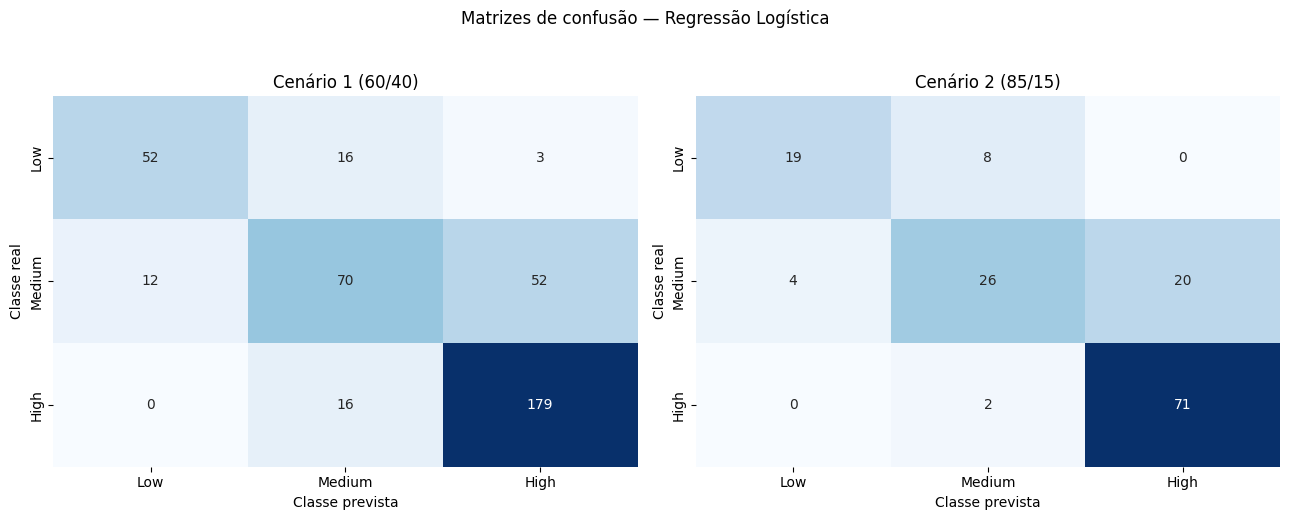


Relatório por classe — Cenário 1 (60/40)


,precision,recall,f1-score,support
Low,0.812,0.732,0.770,71.0
Medium,0.686,0.522,0.593,134.0
High,0.765,0.918,0.834,195.0
macro avg,0.755,0.724,0.733,400.0
weighted avg,0.747,0.752,0.742,400.0
accuracy,,,0.752,400.0



Relatório por classe — Cenário 2 (85/15)


,precision,recall,f1-score,support
Low,0.826,0.704,0.760,27.0
Medium,0.722,0.52,0.605,50.0
High,0.78,0.973,0.866,73.0
macro avg,0.776,0.732,0.744,150.0
weighted avg,0.769,0.773,0.760,150.0
accuracy,,,0.773,150.0


In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for ax, (nome, resultado) in zip(eixos, resultados.items()):
    sns.heatmap(
        resultado["matriz_confusao"],
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=NOMES_CLASSES,
        yticklabels=NOMES_CLASSES,
        ax=ax,
    )
    ax.set_title(nome)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")

fig.suptitle("Matrizes de confusão — Regressão Logística", y=1.03)
plt.tight_layout()
plt.show()

for nome, resultado in resultados.items():
    print(f"\nRelatório por classe — {nome}")
    display(resultado["relatorio_por_classe"].round(3).fillna(""))


## Comparação e interpretação dos resultados

A acurácia mede a proporção total de previsões corretas. Precisão macro e recall macro calculam a métrica em cada classe e depois fazem uma média simples, de modo que cada classe tenha o mesmo peso. Por isso, essas métricas ajudam a identificar situações em que a acurácia geral parece razoável, mas uma das classes é mal reconhecida.

A acurácia do baseline é a referência obtida ao prever sempre a classe mais frequente no conjunto de treinamento. Superar esse baseline é um sinal útil, mas não é suficiente para concluir que o modelo está pronto para uso: também é preciso olhar as métricas por classe, a matriz de confusão e o contexto do problema.

Os limites abaixo são apenas critérios práticos de discussão para este exercício, não padrões universais. A adequação final depende do custo de erros, do balanceamento das classes e do uso pretendido do modelo.

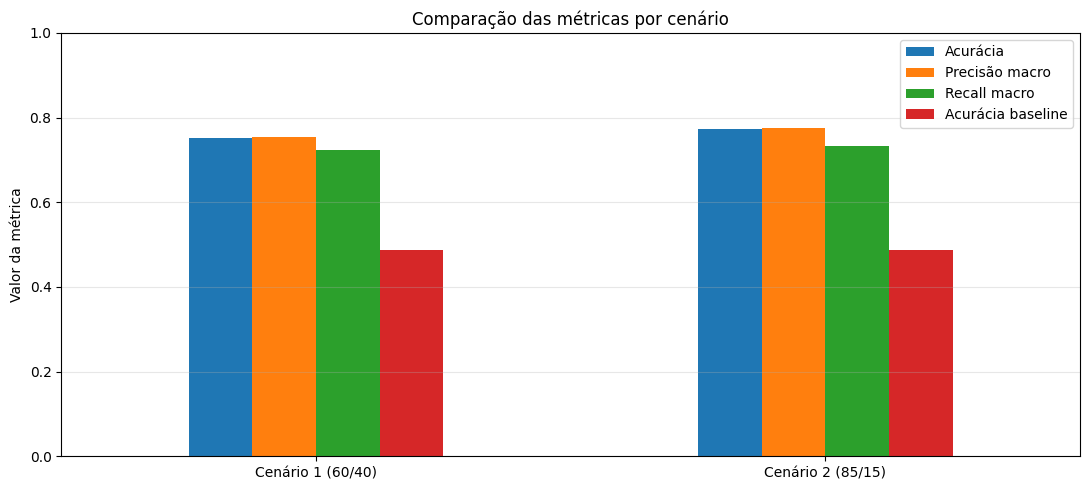


Comparação direta (85/15 menos 60/40):

Acurácia: 0.773 - 0.752 = +0.021
Precisão macro: 0.776 - 0.755 = +0.022
Recall macro: 0.732 - 0.724 = +0.008


In [14]:
# Comparação visual de acurácia, precisão macro e recall macro.
metricas_grafico = resumo_metricas.set_index("Cenário")[[
    "Acurácia", "Precisão macro", "Recall macro", "Acurácia baseline"
]]
ax = metricas_grafico.plot(kind="bar", figsize=(11, 5), ylim=(0, 1), rot=0)
ax.set_title("Comparação das métricas por cenário")
ax.set_ylabel("Valor da métrica")
ax.set_xlabel("")
ax.legend(loc="best")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Diferença entre os dois cenários.
linha_6040 = resumo_metricas.loc[resumo_metricas["Cenário"] == "Cenário 1 (60/40)"].iloc[0]
linha_8515 = resumo_metricas.loc[resumo_metricas["Cenário"] == "Cenário 2 (85/15)"].iloc[0]

print("\nComparação direta (85/15 menos 60/40):\n")
for metrica in ["Acurácia", "Precisão macro", "Recall macro"]:
    val_c1 = linha_6040[metrica]
    val_c2 = linha_8515[metrica]
    diferenca = val_c2 - val_c1
    print(f"{metrica}: {val_c2:.3f} - {val_c1:.3f} = {diferenca:+.3f}")

A avaliação do cenário 85/15 mostrou acurácia maior neste particionamento. Isso pode estar relacionado ao maior volume de treino, mas a comparação também depende da amostra de teste e não prova, por si só, que a proporção 85/15 seja sempre melhor.

Limitações da comparação: os dois cenários mudam simultaneamente o número de exemplos disponíveis para treinar e para testar. O teste maior (40%) produz métricas calculadas em mais observações, geralmente com menor variabilidade amostral, mas deixa menos dados para o ajuste. O teste menor (15%) libera mais dados para treinamento, mas poucas previsões incorretas a mais ou a menos podem alterar as métricas de forma perceptível. Para conclusões mais robustas, seria útil repetir as divisões ou usar validação cruzada, mantendo um conjunto de teste final independente.

## Discussão sobre o Tamanho do Conjunto de Teste (Vantagens e Limitações)

A escolha da proporção entre dados de treino e teste representa um clássico balanço (*trade-off*) no desenvolvimento de modelos de Machine Learning, envolvendo dois aspectos conflitantes: a **qualidade do ajuste do modelo** e a **confiabilidade da avaliação da sua performance**.

---

#### 1. Conjunto de Teste Menor (ex: 15% de teste / 85% de treino)

*   **Vantagens:**
    *   **Mais dados para o treinamento:** O modelo tem acesso a uma maior quantidade e diversidade de exemplos para ajustar seus pesos e interceptos. Em datasets pequenos (como o nosso, com 1000 amostras), dispor de 850 dados de treino em vez de 600 é uma vantagem expressiva que permite ao estimador capturar melhor os padrões reais dos dados.
    *   **Melhor generalização:** Com mais dados de treino, reduz-se o risco de subajuste (*underfitting*), permitindo que o modelo aprenda de forma mais robusta.

*   **Limitações:**
    *   **Menos confiabilidade estatística na avaliação:** Avaliar o modelo em apenas 150 amostras (Cenário 2) faz com que as métricas de validação sejam estatisticamente menos estáveis e altamente sensíveis a pequenas flutuações. Acertos ou erros em pouquíssimas amostras podem alterar drasticamente a acurácia, gerando uma avaliação com alta variância.
    *   **Dificuldade de representação de classes minoritárias:** Se uma das classes for muito rara, um conjunto de teste muito pequeno corre o risco de não conter amostras suficientes dela para uma avaliação de recall e precisão fidedigna.

---

#### 2. Conjunto de Teste Maior (ex: 40% de teste / 60% de treino)

*   **Vantagens:**
    *   **Avaliação de performance altamente confiável e estável:** Avaliar o modelo com 400 amostras (Cenário 1) garante um cálculo de métricas muito mais representativo da realidade de produção. A variância do estimador da métrica de teste é menor, significando que o resultado obtido é estatisticamente mais próximo do erro real do modelo.
    *   **Melhor representatividade:** Há maior garantia de que todas as classes e subgrupos de dados (como combinações de regiões e fontes de energia) estarão bem representados no momento da validação.

*   **Limitações:**
    *   **Privação de dados para o treino:** Ao reter 40% dos dados, restam apenas 600 amostras para o algoritmo aprender. O modelo pode não alcançar seu potencial máximo de performance simplesmente por falta de exemplos históricos suficientes no treinamento, o que pode prejudicar seu desempenho final.